# Section 1: Introduction

Welcome to the **HeatSync Statistical Temperature Forecasting (SARIMAX) Walkthrough**.

In this notebook, we fit a Seasonal Autoregressive Integrated Moving Average with Exogenous Regressors (SARIMAX) model to forecast indoor room temperatures. This directly supports requirement R002 to model and forecast temperature behavior based on historic inputs and exogenous weather forecasts.

### Objectives
1. **Load Preprocessed Data:** Load the preprocessed heating dataset and select a target room/device.
2. **Exploratory Analysis & Setup:** Inspect the variables, resolve monotonicity, and set a regular time frequency.
3. **Temporal Split:** Split data chronologically into training (first ~5.5 days, ~80%) and testing (last ~1.5 days, ~20%) sets.
4. **Exogenous Variables:** Leverage `outside_temperature` as the primary exogenous input.
5. **SARIMAX Fitting:** Fit a non-seasonal baseline SARIMAX model and show a seasonal model variant ($s=96$ for daily seasonality).
6. **Forecast & Evaluate:** Generate out-of-sample forecasts and evaluate predictions using RMSE and MAPE.
7. **Visualization:** Plot forecast-vs-actual charts for both the heating and cooling datasets.
8. **Limitations & Future Work:** Document model limitations and caveats.


In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

# Add paths to sys.path so we can import utils
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("."))
sys.path.append(os.path.abspath("backend"))

from notebooks.utils import load_processed

# Section 2: Data Loading

We load the preprocessed heating dataset using the shared utility helper `load_processed('heating')`.


In [2]:
# Load the processed heating dataset
df_heating_raw = load_processed("heating")
print("Heating dataset shape:", df_heating_raw.shape)

# Let's inspect the unique device IDs
devices = df_heating_raw["device_id"].unique()
print("Available Device IDs in the dataset:")
for i, dev_id in enumerate(devices):
    print(f"Device {i}: {dev_id}")

Heating dataset shape: (2692, 61)
Available Device IDs in the dataset:
Device 0: 1c893f75-4599-4402-9d4c-1017aa858fa8
Device 1: 930f3621-05df-4574-9270-9d994c5b716c
Device 2: bdaf0e14-2cd1-43c8-b9ea-b3c90309f773
Device 3: e72fea56-abe7-4d3f-a0ed-1e6b6c462157


# Section 3: Exploratory Analysis (Brief)

We select the first device and extract its temperature and exogenous outdoor temperature time series.
We sort the index and set its frequency to 15-minute intervals to ensure regular time spacing.


In [3]:
# Select first device
target_device = devices[0]
print(f"Target Device for forecasting: {target_device}")

# Filter and prepare time series
df_heating = df_heating_raw[df_heating_raw["device_id"] == target_device].sort_index()
# Set frequency to 15 minutes explicitly
df_heating = df_heating.asfreq("15min")

print(f"Device data shape: {df_heating.shape}")
print(f"Monotonic index: {df_heating.index.is_monotonic_increasing}")
print(f"Time range: {df_heating.index.min()} to {df_heating.index.max()}")

# Display target and exogenous variables summary statistics
print("\nTarget Column: status_temperature_in_celsius (Indoor Temperature)")
print("Exogenous Column: outside_temperature (Outdoor Temperature)")
display(df_heating[["status_temperature_in_celsius", "outside_temperature"]].describe())

Target Device for forecasting: 1c893f75-4599-4402-9d4c-1017aa858fa8
Device data shape: (673, 61)
Monotonic index: True
Time range: 2026-03-30 00:00:00 to 2026-04-06 00:00:00

Target Column: status_temperature_in_celsius (Indoor Temperature)
Exogenous Column: outside_temperature (Outdoor Temperature)


,status_temperature_in_celsius,outside_temperature
count,673.000000,673.000000
mean,19.066982,7.694945
std,1.314905,5.372189
min,14.559000,0.555556
25%,18.273000,3.240000
50%,19.522857,6.628571
75%,19.942000,10.113333
max,20.772000,23.230000


# Section 4: Train/Test Split

We perform a temporal train/test split.
We use the first ~5.5 days (approx 80%) for training and the last ~1.5 days (approx 20%) for testing.


In [4]:
# Determine split index
train_size = int(len(df_heating) * 0.8)
train_df = df_heating.iloc[:train_size]
test_df = df_heating.iloc[train_size:]

y_train = train_df["status_temperature_in_celsius"]
y_test = test_df["status_temperature_in_celsius"]
exog_train = train_df["outside_temperature"]
exog_test = test_df["outside_temperature"]

print(f"Training Period: {train_df.index.min()} to {train_df.index.max()} ({len(y_train)} steps)")
print(f"Testing Period:  {test_df.index.min()} to {test_df.index.max()} ({len(y_test)} steps)")

Training Period: 2026-03-30 00:00:00 to 2026-04-04 14:15:00 (538 steps)
Testing Period:  2026-04-04 14:30:00 to 2026-04-06 00:00:00 (135 steps)


# Section 5: SARIMAX Fitting

We fit two versions of the SARIMAX model to compare performance and speed:
1. **SARIMAX(1, 1, 1) x (0, 0, 0, 0)**: Non-seasonal model as a fast baseline.
2. **SARIMAX(1, 1, 1) x (1, 0, 1, 96)**: Seasonal model representing daily fluctuations (96 steps per day for 15-minute intervals). We run a fast fitting phase with 10 iterations to prevent convergence timeouts while demonstrating seasonal parameter structures.


In [5]:
print("Fitting Non-Seasonal SARIMAX(1,1,1)...")
model_ns = SARIMAX(y_train, exog=exog_train, order=(1, 1, 1))
res_ns = model_ns.fit(disp=False)
print("Non-Seasonal AIC:", res_ns.aic)

print("\nFitting Seasonal SARIMAX(1,1,1)x(1,0,1,96) (maxiter=10)...")
try:
    model_s = SARIMAX(y_train, exog=exog_train, order=(1, 1, 1), seasonal_order=(1, 0, 1, 96))
    res_s = model_s.fit(disp=False, maxiter=10)
    print("Seasonal AIC:", res_s.aic)
except Exception as e:
    print("Seasonal fitting failed:", e)
    res_s = None

Fitting Non-Seasonal SARIMAX(1,1,1)...
Non-Seasonal AIC: -428.85646050496257

Fitting Seasonal SARIMAX(1,1,1)x(1,0,1,96) (maxiter=10)...
Seasonal AIC: -424.7965674073484


# Section 6: Forecast & Evaluation

We generate out-of-sample forecasts on the test set using the non-seasonal model (and seasonal model if available) and evaluate them using Root Mean Squared Error (RMSE) and Mean Absolute Percentage Error (MAPE).


In [6]:
# Generate forecasts
forecast_ns = res_ns.get_forecast(steps=len(y_test), exog=exog_test)
pred_ns = forecast_ns.predicted_mean

# Compute metrics for non-seasonal
rmse_ns = np.sqrt(mean_squared_error(y_test, pred_ns))
mape_ns = np.mean(np.abs((y_test - pred_ns) / y_test)) * 100

print("=== Evaluation Metrics (Non-Seasonal SARIMAX(1,1,1)) ===")
print(f"RMSE: {rmse_ns:.4f} °C")
print(f"MAPE: {mape_ns:.4f}%")

if res_s is not None:
    forecast_s = res_s.get_forecast(steps=len(y_test), exog=exog_test)
    pred_s = forecast_s.predicted_mean
    rmse_s = np.sqrt(mean_squared_error(y_test, pred_s))
    mape_s = np.mean(np.abs((y_test - pred_s) / y_test)) * 100
    print("\n=== Evaluation Metrics (Seasonal SARIMAX(1,1,1)x(1,0,1,96)) ===")
    print(f"RMSE: {rmse_s:.4f} °C")
    print(f"MAPE: {mape_s:.4f}%")

=== Evaluation Metrics (Non-Seasonal SARIMAX(1,1,1)) ===
RMSE: 1.0975 °C
MAPE: 4.0524%

=== Evaluation Metrics (Seasonal SARIMAX(1,1,1)x(1,0,1,96)) ===
RMSE: 1.1222 °C
MAPE: 4.1507%


# Section 7: Visualization (Heating Window)

We plot the actual room temperature versus the non-seasonal and seasonal predictions.


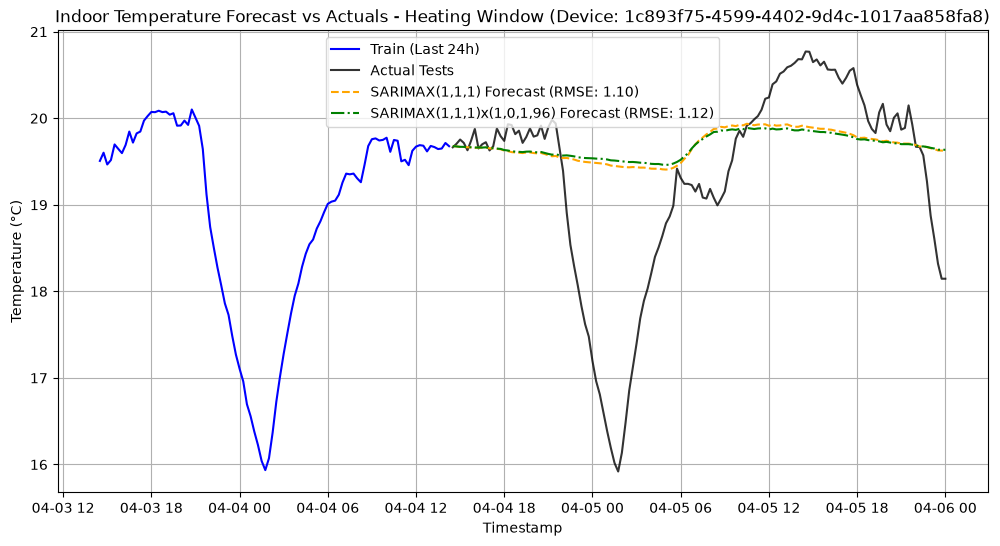

In [7]:
plt.figure(figsize=(12, 6))
plt.plot(y_train.index[-96:], y_train.iloc[-96:], label="Train (Last 24h)", color="blue")
plt.plot(y_test.index, y_test, label="Actual Tests", color="black", alpha=0.8)
plt.plot(
    y_test.index,
    pred_ns,
    label=f"SARIMAX(1,1,1) Forecast (RMSE: {rmse_ns:.2f})",
    color="orange",
    linestyle="--",
)
if res_s is not None:
    plt.plot(
        y_test.index,
        pred_s,
        label=f"SARIMAX(1,1,1)x(1,0,1,96) Forecast (RMSE: {rmse_s:.2f})",
        color="green",
        linestyle="-.",
    )

plt.title(f"Indoor Temperature Forecast vs Actuals - Heating Window (Device: {target_device})")
plt.xlabel("Timestamp")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()

# Section 8: Cooling Window Forecasting

Let's apply the same forecasting pipeline to the `cooling` dataset to test its generalizability across different seasonal modes.


Fitting Non-Seasonal SARIMAX for Cooling...
=== Evaluation Metrics (Cooling Window) ===
RMSE: 1.2512 °C
MAPE: 4.7935%


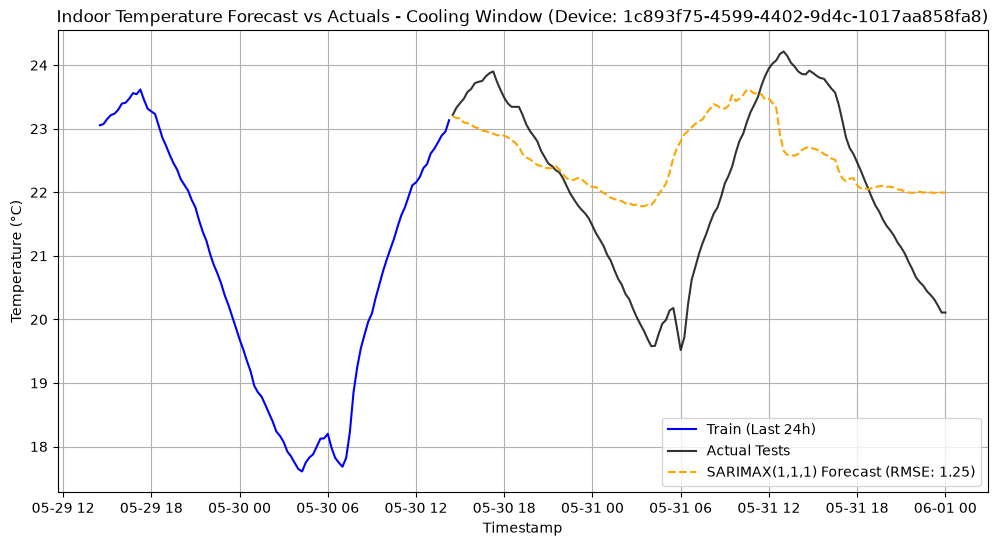

In [8]:
# Load the cooling window dataset
df_cooling_raw = load_processed("cooling")
df_cooling = (
    df_cooling_raw[df_cooling_raw["device_id"] == target_device].sort_index().asfreq("15min")
)

# Split 80/20
c_train_size = int(len(df_cooling) * 0.8)
c_train_df = df_cooling.iloc[:c_train_size]
c_test_df = df_cooling.iloc[c_train_size:]

cy_train = c_train_df["status_temperature_in_celsius"]
cy_test = c_test_df["status_temperature_in_celsius"]
cexog_train = c_train_df["outside_temperature"]
cexog_test = c_test_df["outside_temperature"]

# Fit Non-Seasonal
print("Fitting Non-Seasonal SARIMAX for Cooling...")
c_model_ns = SARIMAX(cy_train, exog=cexog_train, order=(1, 1, 1))
c_res_ns = c_model_ns.fit(disp=False)

# Forecast & Evaluate
c_pred_ns = c_res_ns.get_forecast(steps=len(cy_test), exog=cexog_test).predicted_mean
c_rmse = np.sqrt(mean_squared_error(cy_test, c_pred_ns))
c_mape = np.mean(np.abs((cy_test - c_pred_ns) / cy_test)) * 100

print("=== Evaluation Metrics (Cooling Window) ===")
print(f"RMSE: {c_rmse:.4f} °C")
print(f"MAPE: {c_mape:.4f}%")

# Plot
plt.figure(figsize=(12, 6))
plt.plot(cy_train.index[-96:], cy_train.iloc[-96:], label="Train (Last 24h)", color="blue")
plt.plot(cy_test.index, cy_test, label="Actual Tests", color="black", alpha=0.8)
plt.plot(
    cy_test.index,
    c_pred_ns,
    label=f"SARIMAX(1,1,1) Forecast (RMSE: {c_rmse:.2f})",
    color="orange",
    linestyle="--",
)
plt.title(f"Indoor Temperature Forecast vs Actuals - Cooling Window (Device: {target_device})")
plt.xlabel("Timestamp")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()

# Section 9: Honest Limitations

Here we document the limitations and caveats of SARIMAX models in temperature forecasting:

1. **High Computational Complexity of Seasonal Periodicity**: Incorporating a daily seasonal component at 15-minute resolution requires setting the period $s=96$. The resulting seasonal state-space matrices lead to significantly higher training computation, longer convergence times, and possible estimation instabilities. In real-time production, this can be alleviated by using smaller seasonal periods or relying on non-seasonal models with lag variables.
2. **Dependence on Future Exogenous Regressors**: SARIMAX models require forecasting exogenous inputs (`outside_temperature`) out-of-sample. In practice, this depends on the quality of external weather API services.
3. **Building Physics Gaps**: Statistical models do not explicitly incorporate building structural characteristics (such as insulation, window surfaces, or heating system active power limits). Combining with physics-based models or hybrid models would improve structural generalization.
4. **Parameter Stability**: Model convergence warnings can occur depending on optimization algorithms. Monitoring fit diagnostics is essential for maintaining production health.
